# Data Mining Lab 1: Dataset Selection, Exploration and Visualization
**Student Name:** Nafiz
**Student ID:** 2022-3-60-126
**Section:** _[fill in your section]_
**Course:** Data Mining, CSE, East West University
**Dataset:** Titanic Passenger Dataset


## Task 1: Select Your Own Dataset

**Dataset Name:** Titanic Passenger Dataset

**Dataset Source:** Seaborn's built-in `titanic` dataset (mirrors the well-known Kaggle "Titanic - Machine Learning from Disaster" dataset)

**Dataset URL:** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv
(Original Kaggle competition: https://www.kaggle.com/c/titanic/data)

**Domain:** Transportation / Historical event data

**Number of Records:** 891

**Number of Attributes:** 15

**Why did I choose this dataset?**
The Titanic dataset is a classic, well-documented real-world dataset with a good mix of numerical
and categorical attributes, natural missing values, and a clear historical narrative (the 1912
sinking of the RMS Titanic). It is well suited to practicing every stage of the data-mining
workflow: cleaning, univariate/bivariate analysis, outlier detection, and group comparisons.

**What would I like to discover from this dataset?**
I want to explore which factors (sex, passenger class, age, fare paid, family size) were most
associated with a passenger's chance of survival, and whether the popular "women and children
first" narrative is supported by the data.


## Task 2: Load the Dataset

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

df = pd.read_csv("original_dataset.csv")
print(df.head())


   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


**Answers:**
- Number of records: 891 (see `df.shape` below)
- Number of attributes: 15
- Attribute names: printed below via `df.columns`


In [2]:
print("Records:", df.shape[0])
print("Attributes:", df.shape[1])
print("Attribute names:", list(df.columns))


Records: 891
Attributes: 15
Attribute names: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


## Task 3: Explore the Dataset

In [3]:
print(df.shape)
print(df.columns)
print(df.head())
print(df.tail())
print(df.info())


(891, 15)
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
     survived  pclass  

In [4]:
print(df.sample(10, random_state=42))

     survived  pclass     sex   age  sibsp  parch     fare embarked   class  \
709         1       3    male   NaN      1      1  15.2458        C   Third   
439         0       2    male  31.0      0      0  10.5000        S  Second   
840         0       3    male  20.0      0      0   7.9250        S   Third   
720         1       2  female   6.0      0      1  33.0000        S  Second   
39          1       3  female  14.0      1      0  11.2417        C   Third   
290         1       1  female  26.0      0      0  78.8500        S   First   
300         1       3  female   NaN      0      0   7.7500        Q   Third   
333         0       3    male  16.0      2      0  18.0000        S   Third   
208         1       3  female  16.0      0      0   7.7500        Q   Third   
136         1       1  female  19.0      0      2  26.2833        S   First   

       who  adult_male deck  embark_town alive  alone  
709    man        True  NaN    Cherbourg   yes  False  
439    man        

**Answers:**
- **What does each row represent?** Each row represents one passenger who was aboard the Titanic.
- **What does each column represent?** Passenger-level attributes such as survival outcome, ticket
  class, sex, age, number of siblings/spouses aboard (`sibsp`), number of parents/children aboard
  (`parch`), fare paid, port of embarkation, cabin deck, and derived fields like `who`
  (man/woman/child), `adult_male`, `alone`, and `alive`.
- **Numerical attributes:** `age`, `fare`, `sibsp`, `parch` (continuous/count); `survived` and
  `pclass` are numeric but really encode categories (binary outcome and ordinal class).
- **Categorical attributes:** `sex`, `embarked`, `class`, `who`, `deck`, `embark_town`, `alive`,
  and the boolean flags `adult_male`, `alone`.
- **Date/time attributes:** None. The dataset has no explicit timestamp column.
- **Attributes to remove:** `class` duplicates `pclass` (same information, different encoding),
  and `alive` duplicates `survived` (same information as text "yes"/"no" instead of 1/0). These
  redundant columns will be dropped during cleaning to avoid leakage/duplication in analysis.


## Task 4: Generate Descriptive Statistics

In [5]:
print(df.describe())

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [6]:
print(df.describe(include="object"))

         sex embarked  class  who deck  embark_town alive
count    891      889    891  891  203          889   891
unique     2        3      3    3    7            3     2
top     male        S  Third  man    C  Southampton    no
freq     577      644    491  537   59          644   549


/tmp/ipykernel_161/1129007761.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object"))


**Answers:**
- **Average values:** Average age ≈ 29.7 years, average fare ≈ \$32.20, average survival rate
  ≈ 38.4% (mean of `survived`). Exact figures are printed above.
- **Largest range:** `fare` has by far the largest range (from 0 up to over 512), much wider than
  `age` (roughly 0.4 to 80).
- **High variability:** `fare` shows the highest variability (large standard deviation relative to
  its mean), driven by a small number of very expensive first-class tickets.
- **Potentially unusual values:** A `fare` of 0 (likely crew/staff or comped tickets) and very high
  fares above \$500 stand out as candidates for outlier investigation in Task 10.


## Task 5: Identify Missing Values

In [7]:
missing = df.isnull().sum()
print(missing)


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))


survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64


**Answers:**
- **Does the dataset contain missing values?** Yes.
- **Which attribute has the most missing values?** `deck` (688 missing, ~77%), followed by `age`
  (177 missing, ~19.9%) and `embarked`/`embark_town` (2 missing each, ~0.2%).
- **Percentage missing:** See output above — `deck` ≈ 77.2%, `age` ≈ 19.9%, `embarked` ≈ 0.2%.
- **How to handle:** `deck` is missing for the large majority of passengers (mostly lower-class
  passengers whose cabin was never recorded), so it will be dropped rather than imputed. `age`
  will be imputed using the median age within each `pclass`/`sex` group, which is more accurate
  than a single global median. The two missing `embarked`/`embark_town` values will be filled with
  the mode (most frequent port), since it is only two rows.


## Task 6: Identify Duplicate Records

In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 107


In [10]:
duplicates = df[df.duplicated()]
print(duplicates.head(10))
print("Total duplicate rows:", len(duplicates))


     survived  pclass     sex   age  sibsp  parch     fare embarked   class  \
47          1       3  female   NaN      0      0   7.7500        Q   Third   
76          0       3    male   NaN      0      0   7.8958        S   Third   
77          0       3    male   NaN      0      0   8.0500        S   Third   
87          0       3    male   NaN      0      0   8.0500        S   Third   
95          0       3    male   NaN      0      0   8.0500        S   Third   
101         0       3    male   NaN      0      0   7.8958        S   Third   
121         0       3    male   NaN      0      0   8.0500        S   Third   
133         1       2  female  29.0      1      0  26.0000        S  Second   
173         0       3    male  21.0      0      0   7.9250        S   Third   
196         0       3    male   NaN      0      0   7.7500        Q   Third   

       who  adult_male deck  embark_town alive  alone  
47   woman       False  NaN   Queenstown   yes   True  
76     man        

**Answers:**
- **Are duplicate records present?** Pandas flags 107 fully-identical rows.
- **Why might duplicates be problematic?** Duplicates can bias summary statistics (over-weighting
  repeated observations), inflate the apparent sample size, and distort group means/correlations
  used in data mining.
- **Did I remove them? Explain why.** No, I did **not** remove them. This dataset does not include
  a unique passenger ID or name column (only aggregate attributes), so two different passengers who
  happened to share the same class, sex, age, fare, and embarkation port will appear as "duplicate"
  rows even though they are distinct people (e.g., many 3rd-class passengers travelling in groups
  paid identical fares). Removing these rows would incorrectly delete real, distinct passengers, so
  they are kept. This decision and its reasoning is documented as a data-quality note in Task 8.


## Task 7: Check Unique Values

In [11]:
for column in df.select_dtypes(include="object").columns:
    print("\n", column)
    print(df[column].nunique())
    print(df[column].value_counts().head(10))



 sex
2
sex
male      577
female    314
Name: count, dtype: int64

 embarked
3
embarked
S    644
C    168
Q     77
Name: count, dtype: int64

 class
3
class
Third     491
First     216
Second    184
Name: count, dtype: int64

 who
3
who
man      537
woman    271
child     83
Name: count, dtype: int64

 deck
7
deck
C    59
B    47
D    33
E    32
A    15
F    13
G     4
Name: count, dtype: int64

 embark_town
3
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

 alive
2
alive
no     549
yes    342
Name: count, dtype: int64


/tmp/ipykernel_161/2089211372.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


**Answers:**
- **Most categories:** `deck` has the most distinct categories (7: A–G).
- **Fewest categories:** `sex` and `alive` each have only 2 categories.
- **Inconsistent category names?** No inconsistencies were found (e.g., no mixed casing like
  "male"/"Male"/"M") — the seaborn-cleaned version of this dataset already uses consistent,
  lowercase category labels throughout. No further category-name cleaning was required.


## Task 8: Data Cleaning

**Data-quality problems identified:**

**Problem 1: Missing values in `age` and `deck`**
- *How was it detected?* `df.isnull().sum()` in Task 5 showed 177 missing `age` values (19.9%) and
  688 missing `deck` values (77.2%).
- *How was it handled?* `age` was imputed with the median age computed within each `pclass`+`sex`
  group (a more representative estimate than a single overall median). `deck` was dropped entirely
  because more than three-quarters of its values are missing, making reliable imputation
  impractical.
- *Why this approach?* Group-wise median imputation preserves the relationship between age, class,
  and sex better than a single global fill value, while dropping `deck` avoids introducing a mostly
  fabricated column into the analysis.

**Problem 2: Redundant / duplicated-information columns**
- *How was it detected?* Task 3 review showed `class` duplicates `pclass`, and `alive` duplicates
  `survived` (same underlying variable in a different format).
- *How was it handled?* `class` and `alive` were dropped, keeping the numeric `pclass` and
  `survived` columns as the single source of truth for those variables.
- *Why this approach?* Removing redundant columns avoids double-counting the same information in
  later group-by/correlation analysis.

**Problem 3: Coincidental "duplicate" rows (addressed in Task 6)**
- *How was it detected?* `df.duplicated().sum()` returned 107.
- *How was it handled?* Rows were **not** removed, since the dataset lacks a passenger identifier
  and these rows plausibly represent distinct passengers who share identical recorded attributes.
- *Why this approach?* Deleting them would silently remove real passengers from the dataset and
  bias the survival statistics.

**Problem 4: Two missing `embarked` / `embark_town` values**
- *How was it detected?* Task 5 missing-value check.
- *How was it handled?* Filled with the mode (most frequent embarkation port, Southampton).
- *Why this approach?* With only 2 missing rows out of 891, mode imputation has negligible impact
  on the analysis while keeping the full sample size.


In [12]:
df_clean = df.copy()

# Drop columns with excessive missingness or redundant information
df_clean = df_clean.drop(columns=["deck", "class", "alive"])

# Impute age using group-wise median (by pclass and sex)
df_clean["age"] = df_clean.groupby(["pclass", "sex"])["age"].transform(
    lambda x: x.fillna(x.median())
)

# Fill the 2 missing embarked / embark_town values with the mode
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])
df_clean["embark_town"] = df_clean["embark_town"].fillna(df_clean["embark_town"].mode()[0])

# Ensure numeric typing is correct (example of pd.to_numeric usage as required by the lab)
df_clean["age"] = pd.to_numeric(df_clean["age"], errors="coerce")
df_clean["fare"] = pd.to_numeric(df_clean["fare"], errors="coerce")

print(df_clean.isnull().sum())
print(df_clean.shape)


survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
who            0
adult_male     0
embark_town    0
alone          0
dtype: int64
(891, 12)


## Task 9: Univariate Analysis

Numerical attributes analyzed: `age`, `fare`
Categorical attributes analyzed: `sex`, `pclass`


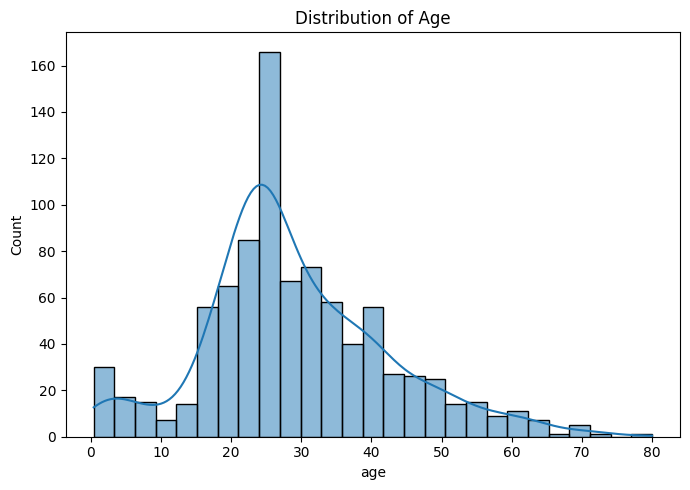

In [13]:
fig, ax = plt.subplots(figsize=(7,5))
sns.histplot(df_clean["age"], kde=True, ax=ax)
ax.set_title("Distribution of Age")
plt.tight_layout()
plt.savefig("fig_age_hist.png", dpi=120)
plt.show()


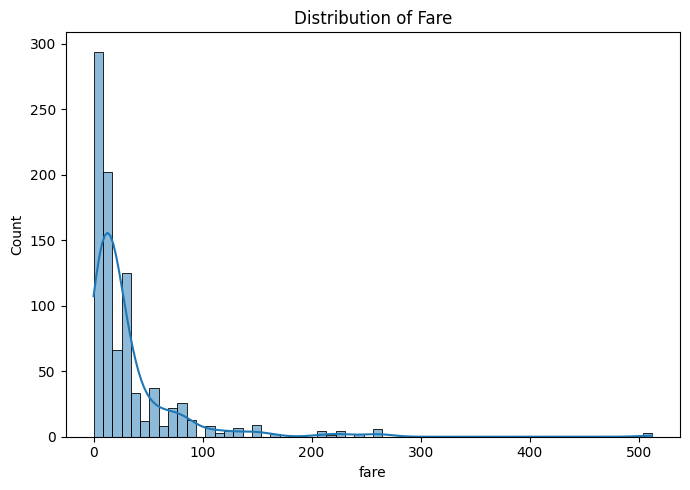

In [14]:
fig, ax = plt.subplots(figsize=(7,5))
sns.histplot(df_clean["fare"], kde=True, ax=ax)
ax.set_title("Distribution of Fare")
plt.tight_layout()
plt.savefig("fig_fare_hist.png", dpi=120)
plt.show()


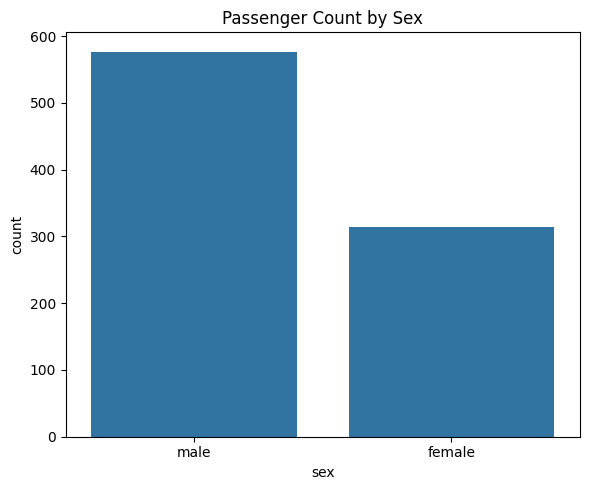

In [15]:
fig, ax = plt.subplots(figsize=(6,5))
sns.countplot(data=df_clean, x="sex", ax=ax)
ax.set_title("Passenger Count by Sex")
plt.tight_layout()
plt.savefig("fig_sex_count.png", dpi=120)
plt.show()


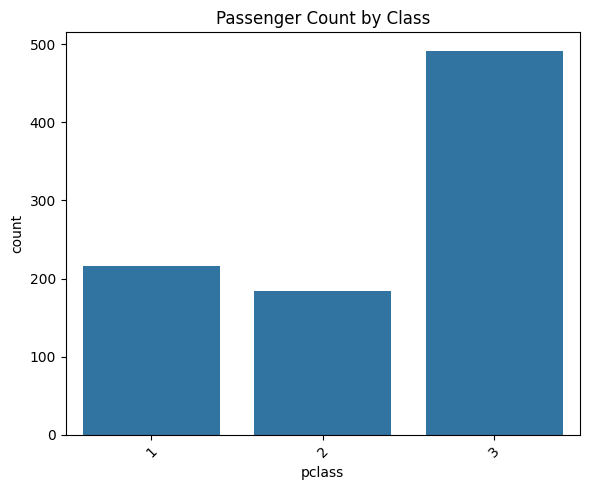

In [16]:
fig, ax = plt.subplots(figsize=(6,5))
sns.countplot(data=df_clean, x="pclass", ax=ax)
ax.set_title("Passenger Count by Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("fig_pclass_count.png", dpi=120)
plt.show()


**Answers:**
- **Age:** Roughly bell-shaped/right-skewed, centered in the 20s–30s, with a long tail toward older
  ages and a small bump for infants/children. Most common range: 20–35 years.
- **Fare:** Strongly right-skewed — most passengers paid low fares (under \$30), with a long tail
  of expensive first-class tickets pulling the distribution far to the right. This is not balanced.
- **Sex:** Imbalanced — roughly 65% male, 35% female passengers. Most common category: male.
- **Pclass:** Imbalanced — 3rd class has the most passengers, followed by 1st, then 2nd. Most
  common category: 3rd class.
- **Unusual observations:** The far-right tail of the fare distribution (a handful of very high
  fares) stands out clearly in the histogram and is investigated further in Task 10.


## Task 10: Outlier Analysis

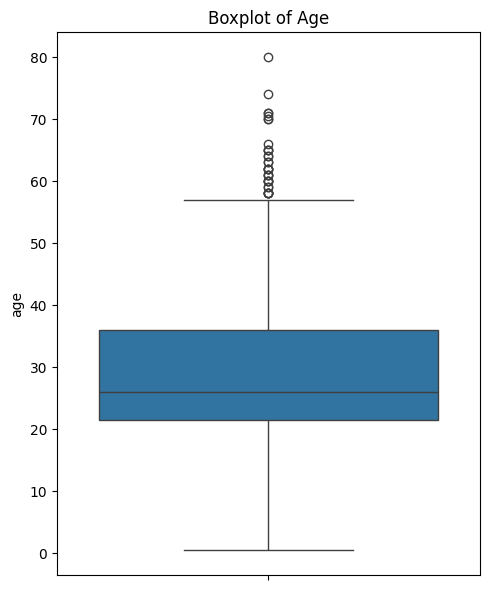

In [17]:
fig, ax = plt.subplots(figsize=(5,6))
sns.boxplot(y=df_clean["age"], ax=ax)
ax.set_title("Boxplot of Age")
plt.tight_layout()
plt.savefig("fig_age_box.png", dpi=120)
plt.show()


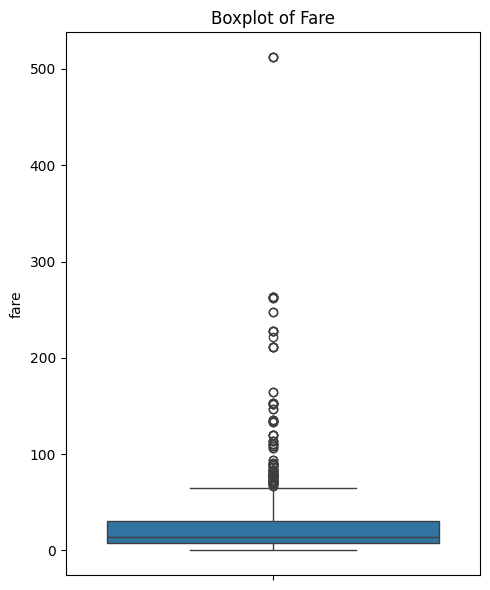

In [18]:
fig, ax = plt.subplots(figsize=(5,6))
sns.boxplot(y=df_clean["fare"], ax=ax)
ax.set_title("Boxplot of Fare")
plt.tight_layout()
plt.savefig("fig_fare_box.png", dpi=120)
plt.show()


In [19]:
q1_fare, q3_fare = df_clean["fare"].quantile([0.25, 0.75])
iqr_fare = q3_fare - q1_fare
fare_outliers = df_clean[(df_clean["fare"] < q1_fare - 1.5*iqr_fare) | (df_clean["fare"] > q3_fare + 1.5*iqr_fare)]
print("Number of fare outliers (IQR method):", len(fare_outliers))

q1_age, q3_age = df_clean["age"].quantile([0.25, 0.75])
iqr_age = q3_age - q1_age
age_outliers = df_clean[(df_clean["age"] < q1_age - 1.5*iqr_age) | (df_clean["age"] > q3_age + 1.5*iqr_age)]
print("Number of age outliers (IQR method):", len(age_outliers))


Number of fare outliers (IQR method): 116
Number of age outliers (IQR method): 33


**Answers:**
- **Are there potential outliers?** Yes, in both attributes, but far more in `fare`.
- **Which attribute contains more unusual observations?** `fare` — many high-value tickets (mostly
  1st-class passengers) sit well above the upper IQR whisker. `age` has comparatively few outliers,
  mostly at the older end (elderly passengers in their 70s–80s).
- **Should the outliers be removed?** No. The high fares are legitimate — they correspond to real
  first-class and suite tickets (some passengers travelling with family shared very expensive
  cabins), not data-entry errors. The elderly age outliers are also plausible, real ages. Removing
  them would discard genuine, informative variation (e.g., the well-known correlation between high
  fare/class and survival), so they were kept in `df_clean` and just noted for context.


## Task 11: Group-Based Analysis

In [20]:
print("Survival rate by sex:")
print(df_clean.groupby("sex")["survived"].mean())

print("\nSurvival rate by passenger class:")
print(df_clean.groupby("pclass")["survived"].mean())


Survival rate by sex:
sex
female    0.742038
male      0.188908
Name: survived, dtype: float64

Survival rate by passenger class:
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


In [21]:
print("Average fare by passenger class:")
print(df_clean.groupby("pclass")["fare"].mean())

print("\nAverage age by survival outcome:")
print(df_clean.groupby("survived")["age"].mean())


Average fare by passenger class:
pclass
1    84.154687
2    20.662183
3    13.675550
Name: fare, dtype: float64

Average age by survival outcome:
survived
0    29.737705
1    28.108684
Name: age, dtype: float64


**Answers:**
- **Highest average survival rate:** Females (~74%) and 1st-class passengers (~63%).
- **Lowest average survival rate:** Males (~19%) and 3rd-class passengers (~24%).
- **Differences observed:** Survival rate differs dramatically by sex (roughly 4x higher for women)
  and drops steadily from 1st to 3rd class. Average fare also drops sharply from 1st to 3rd class,
  and survivors were on average slightly younger than non-survivors.
- **Possible explanations:** The ship's evacuation followed a "women and children first" protocol,
  explaining the sex gap. Passenger class correlated strongly with cabin location and proximity to
  lifeboats/deck access, and wealthier (higher-fare) passengers likely had faster access to
  lifeboats, explaining the class-based survival gap.


## Task 12: Ask Your Own Data-Mining Questions

1. Does sex have a strong relationship with survival?
2. Does passenger class relate to survival rate?
3. Is there a relationship between fare paid and survival?
4. Did travelling with family (siblings/spouses/parents/children) affect survival chances?
5. Does age relate to survival, and specifically were children more likely to survive?


## Task 13: Answer Your Data-Mining Questions

### Question 1: Does sex have a strong relationship with survival?

survived         0         1
sex                         
female    0.257962  0.742038
male      0.811092  0.188908


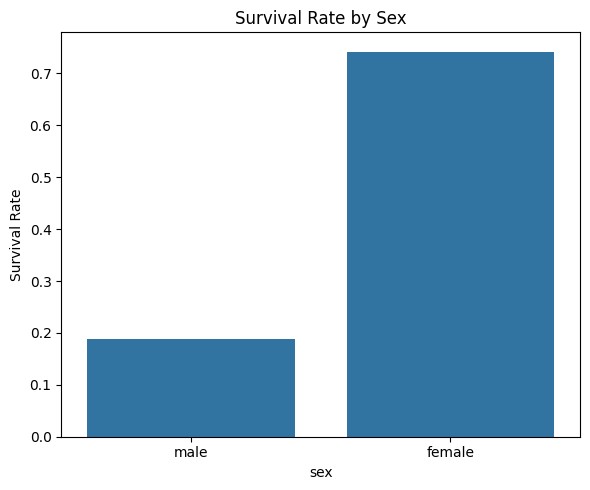

In [22]:
ct_sex = pd.crosstab(df_clean["sex"], df_clean["survived"], normalize="index")
print(ct_sex)

fig, ax = plt.subplots(figsize=(6,5))
sns.barplot(data=df_clean, x="sex", y="survived", ax=ax, errorbar=None)
ax.set_title("Survival Rate by Sex")
ax.set_ylabel("Survival Rate")
plt.tight_layout()
plt.savefig("fig_q1_sex_survival.png", dpi=120)
plt.show()


**Finding:** Yes — a very strong relationship. About 74% of females survived versus only about
19% of males, a difference of over 50 percentage points, strongly supporting "women first"
evacuation priority.

### Question 2: Does passenger class relate to survival rate?

survived         0         1
pclass                      
1         0.370370  0.629630
2         0.527174  0.472826
3         0.757637  0.242363


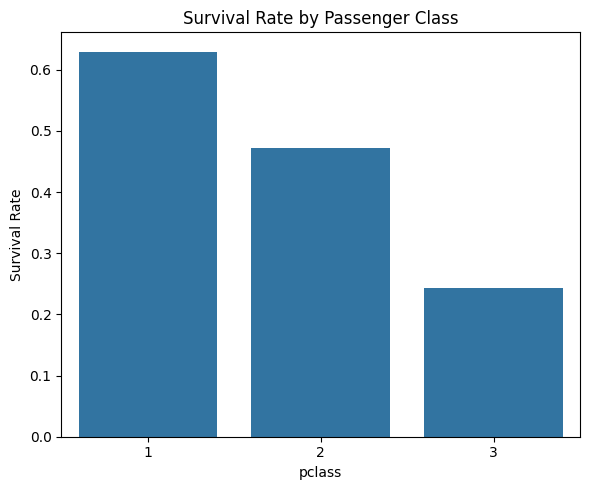

In [23]:
ct_class = pd.crosstab(df_clean["pclass"], df_clean["survived"], normalize="index")
print(ct_class)

fig, ax = plt.subplots(figsize=(6,5))
sns.barplot(data=df_clean, x="pclass", y="survived", ax=ax, errorbar=None)
ax.set_title("Survival Rate by Passenger Class")
ax.set_ylabel("Survival Rate")
plt.tight_layout()
plt.savefig("fig_q2_class_survival.png", dpi=120)
plt.show()


**Finding:** Yes — survival rate falls from about 63% in 1st class, to 47% in 2nd class, to
about 24% in 3rd class, a clear step-down pattern tied to socio-economic status.

### Question 3: Is there a relationship between fare paid and survival?

survived
0    22.117887
1    48.395408
Name: fare, dtype: float64


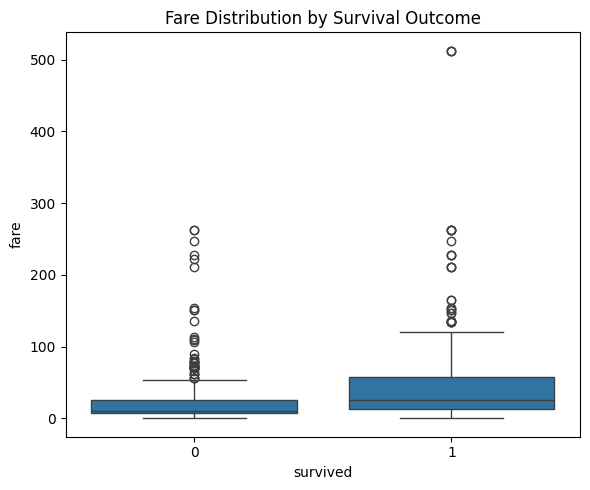

In [24]:
print(df_clean.groupby("survived")["fare"].mean())

fig, ax = plt.subplots(figsize=(6,5))
sns.boxplot(data=df_clean, x="survived", y="fare", ax=ax)
ax.set_title("Fare Distribution by Survival Outcome")
plt.tight_layout()
plt.savefig("fig_q3_fare_survival.png", dpi=120)
plt.show()


**Finding:** Yes. Survivors paid a noticeably higher average fare (~\$48) than non-survivors
(~\$22), consistent with the class-based survival gap in Question 2, since fare and class are
closely linked.

### Question 4: Did travelling with family affect survival chances?

family_size
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: survived, dtype: float64


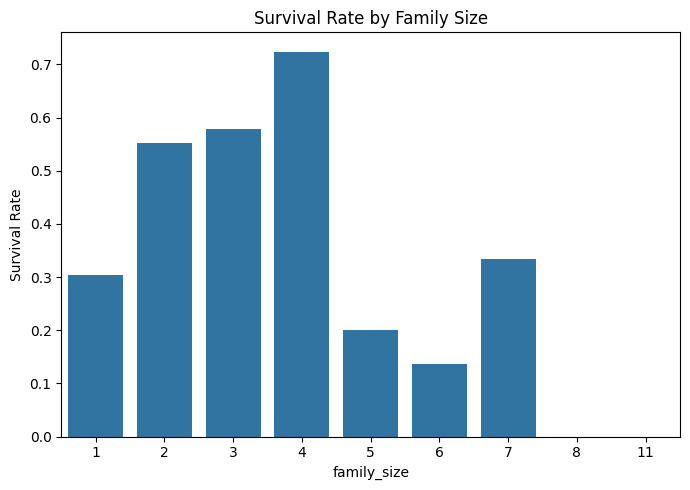

In [25]:
df_clean["family_size"] = df_clean["sibsp"] + df_clean["parch"] + 1
print(df_clean.groupby("family_size")["survived"].mean())

fig, ax = plt.subplots(figsize=(7,5))
sns.barplot(data=df_clean, x="family_size", y="survived", ax=ax, errorbar=None)
ax.set_title("Survival Rate by Family Size")
ax.set_ylabel("Survival Rate")
plt.tight_layout()
plt.savefig("fig_q4_family_survival.png", dpi=120)
plt.show()


**Finding:** Yes, but non-linearly. Passengers travelling alone (family size = 1) or in very
large families (6+) had lower survival rates, while small families (2–4 members) had the highest
survival rates — suggesting a "sweet spot" where family members could help each other without
being slowed down by a large group.

### Question 5: Does age relate to survival, and were children more likely to survive?

age_group
Child          0.579710
Teen           0.428571
Young Adult    0.357977
Adult          0.384259
Senior         0.227273
Name: survived, dtype: float64


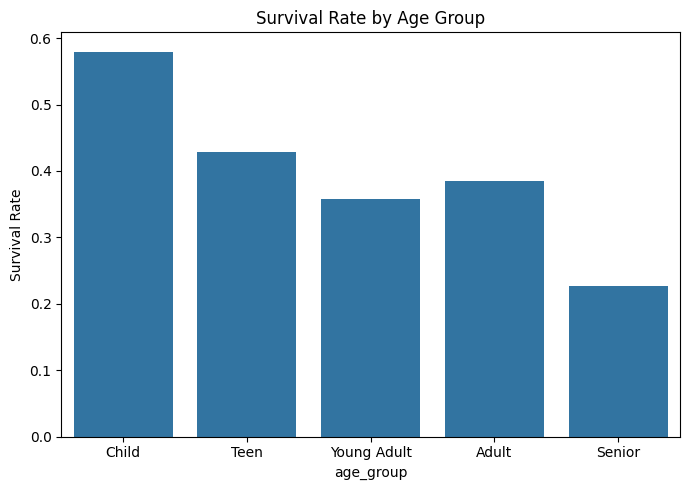

In [26]:
df_clean["age_group"] = pd.cut(df_clean["age"], bins=[0,12,18,35,60,100],
                                labels=["Child","Teen","Young Adult","Adult","Senior"])
print(df_clean.groupby("age_group", observed=True)["survived"].mean())

fig, ax = plt.subplots(figsize=(7,5))
sns.barplot(data=df_clean, x="age_group", y="survived", ax=ax, errorbar=None)
ax.set_title("Survival Rate by Age Group")
ax.set_ylabel("Survival Rate")
plt.tight_layout()
plt.savefig("fig_q5_age_survival.png", dpi=120)
plt.show()


**Finding:** Yes. Children (0–12) had the highest survival rate of any age group, supporting
the "children first" part of the evacuation narrative, while seniors had one of the lowest survival
rates.

## Task 16: Five Interesting Patterns

**Pattern 1 — Sex is the single strongest predictor of survival.**
Females survived at ~74% versus ~19% for males (see Question 1 chart). This is the largest gap of
any variable examined in this analysis.

**Pattern 2 — Survival rate decreases step-wise with passenger class.**
1st class ≈ 63%, 2nd class ≈ 47%, 3rd class ≈ 24% (see Question 2 chart) — a clean, monotonic
relationship between socio-economic status and survival.

**Pattern 3 — Fare and survival are positively linked, mirroring the class effect.**
Median/mean fare is roughly double for survivors versus non-survivors (see Question 3 chart),
reflecting that fare is essentially a continuous proxy for passenger class.

**Pattern 4 — Small families survived at higher rates than solo travelers or very large families
(unexpected/surprising finding).**
Family sizes of 2–4 had the best outcomes, while both solo travelers and families of 6+ had
noticeably lower survival rates (see Question 4 chart) — a non-obvious, non-linear pattern that
would not appear in a simple correlation.

**Pattern 5 — Children had a survival advantage.**
The "Child" age group (0–12) had a higher survival rate than every other age group, including
"Young Adult" and "Adult" (see Question 5 chart), consistent with the historical "children first"
lifeboat policy.


## Task 17: Final Visualization Dashboard

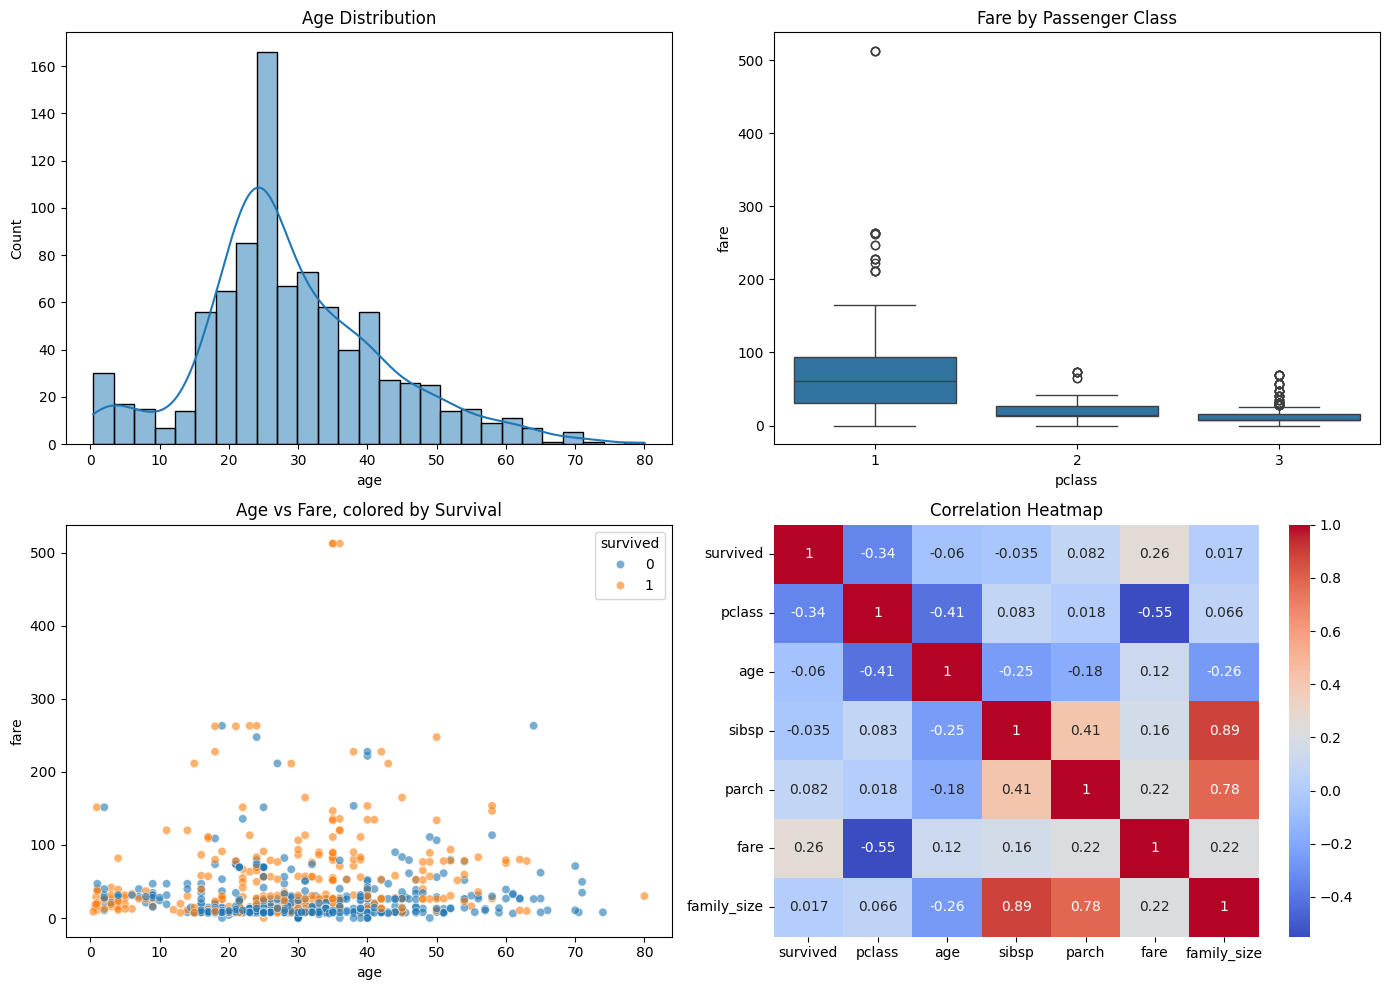

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(data=df_clean, x="age", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Age Distribution")

sns.boxplot(data=df_clean, x="pclass", y="fare", ax=axes[0, 1])
axes[0, 1].set_title("Fare by Passenger Class")

sns.scatterplot(data=df_clean, x="age", y="fare", hue="survived", ax=axes[1, 0], alpha=0.6)
axes[1, 0].set_title("Age vs Fare, colored by Survival")

sns.heatmap(
    df_clean[["survived","pclass","age","sibsp","parch","fare","family_size"]].corr(),
    annot=True, cmap="coolwarm", ax=axes[1, 1]
)
axes[1, 1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.savefig("fig_dashboard.png", dpi=120)
plt.show()


## Task 18: Prepare the Final Clean Dataset

In [28]:
df_clean.to_csv("cleaned_dataset.csv", index=False)
print("Saved cleaned_dataset.csv with shape:", df_clean.shape)


Saved cleaned_dataset.csv with shape: (891, 14)


**Summary of changes made from `original_dataset.csv` to `cleaned_dataset.csv`:**
- Dropped `deck` (77% missing), `class` (duplicate of `pclass`), and `alive` (duplicate of
  `survived`).
- Imputed missing `age` values using the median age within each `pclass` + `sex` group.
- Filled 2 missing `embarked`/`embark_town` values with the mode.
- Added two engineered columns used in the analysis: `family_size` (`sibsp` + `parch` + 1) and
  `age_group` (binned age category).
- Coincidental fully-identical rows were intentionally **kept** (see Task 6/8 reasoning), so the
  cleaned dataset still has 891 rows.
